In [2]:
import tensorflow as tf
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
x_test.shape

(10000, 28, 28)

In [5]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
input_shape = (28, 28, 1)

In [6]:
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

In [7]:
x_train /= 255
x_test /= 255

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D
model = Sequential()
model.add(Conv2D(28, kernel_size=(3,3), input_shape=input_shape))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation=tf.nn.relu))
model.add(Dropout(0.2))
model.add(Dense(10,activation=tf.nn.softmax))

In [9]:
# Configure the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model and save the training history
history = model.fit(
    x=x_train,
    y=y_train,
    epochs=10,
    validation_data=(x_test, y_test)
)

Epoch 1/10
1875/1875 [==============================] - 14s 7ms/step - loss: 0.2183 - accuracy: 0.9352 - val_loss: 0.0834 - val_accuracy: 0.9742
Epoch 2/10
1875/1875 [==============================] - 14s 8ms/step - loss: 0.0873 - accuracy: 0.9735 - val_loss: 0.0615 - val_accuracy: 0.9805
Epoch 3/10
1875/1875 [==============================] - 17s 9ms/step - loss: 0.0607 - accuracy: 0.9813 - val_loss: 0.0558 - val_accuracy: 0.9829
Epoch 4/10
1875/1875 [==============================] - 17s 9ms/step - loss: 0.0467 - accuracy: 0.9854 - val_loss: 0.0570 - val_accuracy: 0.9819
Epoch 5/10
1875/1875 [==============================] - 17s 9ms/step - loss: 0.0369 - accuracy: 0.9881 - val_loss: 0.0509 - val_accuracy: 0.9853
Epoch 6/10
1875/1875 [==============================] - 15s 8ms/step - loss: 0.0299 - accuracy: 0.9895 - val_loss: 0.0652 - val_accuracy: 0.9798
Epoch 7/10
1875/1875 [==============================] - 15s 8ms/step - loss: 0.0244 - accuracy: 0.9917 - val_loss: 0.0576 - val_ac

In [10]:
model.evaluate(x_test, y_test)

313/313 [==============================] - 1s 3ms/step - loss: 0.0626 - accuracy: 0.9845


[0.06261758506298065, 0.984499990940094]

In [11]:
# Predict the first test image
predictions = model.predict(x_test[:1])

# Get the predicted digit
predicted_digit = predictions.argmax(axis=1)[0]

# Get the actual digit
actual_digit = y_test[0]

print("Predicted digit:", predicted_digit)
print("Actual digit:", actual_digit)

Predicted digit: 7
Actual digit: 7


In [12]:
# Visualization libraries
import matplotlib.pyplot as plt
import pydot
import seaborn as sns

#Evaluation library
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [14]:
# Predict digits for all test images
y_predict = model.predict(x_test)

# Convert prediction scores into digit labels
import numpy as np
y_predicts = np.argmax(y_predict, axis=1)

# Actual digit labels
y_test_digit_eval = y_test

print("Predictions:", y_predicts[:10])
print("Actual labels:", y_test_digit_eval[:10])

Predictions: [7 2 1 0 4 1 4 9 5 9]
Actual labels: [7 2 1 0 4 1 4 9 5 9]


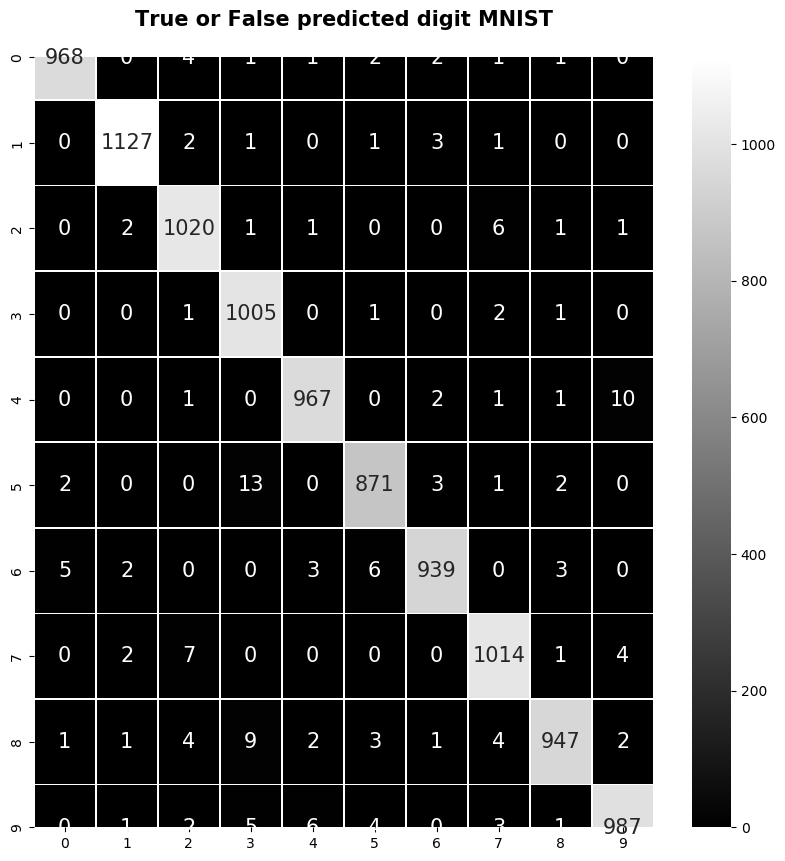

In [15]:
#Confusion matrix for CNN Digit MNIST
con_mat=confusion_matrix(y_test_digit_eval,y_predicts)
plt.style.use('seaborn-deep')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size': 15},linewidths=0.5,fmt="d",cmap="gray")
plt.title('True or False predicted digit MNIST\n',fontweight='bold',fontsize=15)
plt.show()

In [16]:
from sklearn.metrics import classification_report

print(classification_report(y_test_digit_eval,y_predicts))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.99      0.98      1032
           3       0.97      1.00      0.98      1010
           4       0.99      0.98      0.99       982
           5       0.98      0.98      0.98       892
           6       0.99      0.98      0.98       958
           7       0.98      0.99      0.98      1028
           8       0.99      0.97      0.98       974
           9       0.98      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



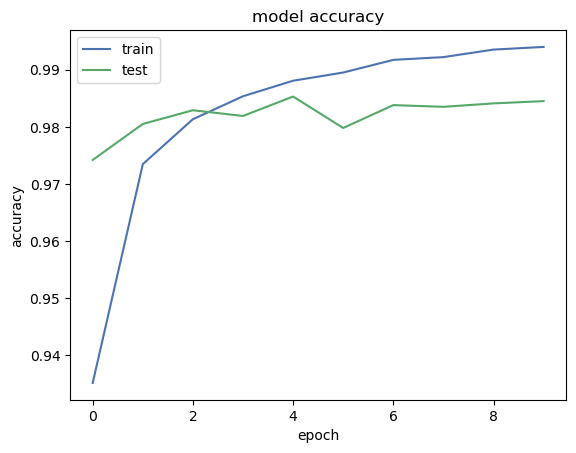

In [17]:
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()


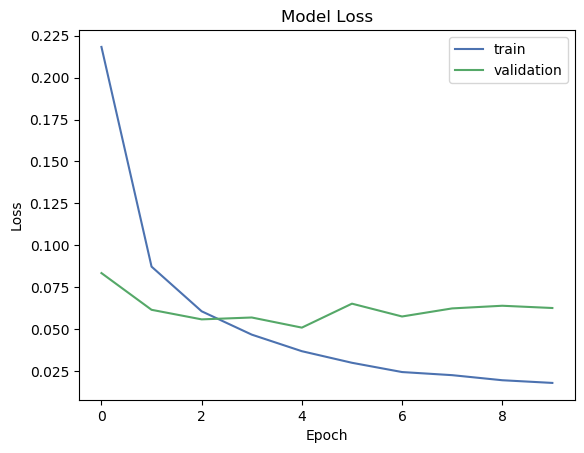

In [20]:
# Plot training and validation loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='best')
plt.show()

In [26]:
# Predict one image (the 4th image in the test dataset)
y_predict_single = model.predict(
    x_test[[0]]
)

# Convert prediction scores into a digit label
y_predicts_single = np.argmax(
    y_predict_single,
    axis=1
)

# Get the actual label of the 4th image
actual_digit = y_test[0]

# Display the results
print("Predicted digit:", y_predicts_single[0])
print("Actual digit:", actual_digit)

Predicted digit: 7
Actual digit: 7


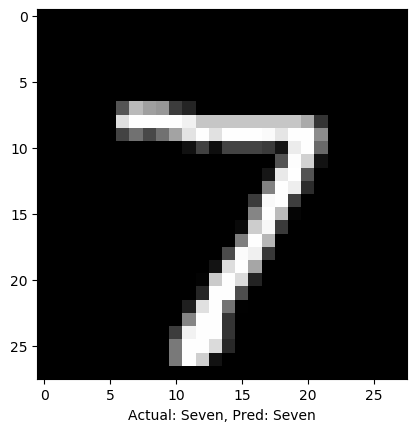

In [27]:
col_names = [
    'Zero', 'One', 'Two', 'Three', 'Four',
    'Five', 'Six', 'Seven', 'Eight', 'Nine'
]

# Display the 4th test image
plt.imshow(
    x_test[0].reshape(28, 28),
    cmap='gray'
)

# Display the actual and predicted digits
plt.xlabel(
    "Actual: {}, Pred: {}".format(
        col_names[y_test[0]],
        col_names[y_predicts_single[0]]
    )
)

plt.show()